<a href="https://colab.research.google.com/github/faisu6339-glitch/LLMs/blob/main/Lanchain_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Models in LangChain

LangChain provides standard interfaces and integrations for two main types of models:

1. **Language Models**: Models that take text as input and return text as output.
2. **Embedding Models**: Models that take text as input and return a list of floats (vectors) representing the semantic meaning of the text.

---

## 1. Language Models

In LangChain, language models are divided into two categories:

### A. LLMs (Text Completion Models)
* **Input**: A prompt string.
* **Output**: A completion string.
* **Use Case**: Traditional models that predict the next tokens (e.g., legacy GPT-3 models like `text-davinci-003`). *Note: Most modern APIs have shifted focus toward Chat Models.*

### B. Chat Models
* **Input**: A list of structured messages (`SystemMessage`, `HumanMessage`, `AIMessage`).
* **Output**: An `AIMessage` containing the model's response.
* **Use Case**: Modern conversational models (e.g., Gemini, GPT-4, Claude) that are fine-tuned for multi-turn dialogue.

---

## 2. Embedding Models

Embedding models convert text into a dense vector representation (an array of numbers).

* **How they work**: They capture the semantic meaning of words, sentences, or paragraphs in a high-dimensional vector space.
* **Key capabilities in LangChain**:
  * `embed_documents(texts)`: Embeds multiple texts (usually for indexing in a vector database).
  * `embed_query(text)`: Embeds a single query string (used to search the database at runtime).
* **Use Cases**: Retrieval Augmented Generation (RAG), semantic search, clustering, and anomaly detection.

## Code Example: Using Chat Models and Embeddings in LangChain

Let's write a code demonstration. We will install the necessary LangChain packages and use a local or API-based setup to demonstrate how to instantiate and call both a Chat Model and an Embedding Model.

In [1]:
!pip install -q langchain-core langchain-community

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
# Example of how schemas and interfaces are structured in LangChain
from langchain_core.messages import HumanMessage, SystemMessage

print("1. Structuring Chat Messages:")
messages = [
    SystemMessage(content="You are a helpful assistant."),
    HumanMessage(content="Explain embeddings in one short sentence.")
]
for msg in messages:
    print(f"{type(msg).__name__}: {msg.content}")


1. Structuring Chat Messages:
SystemMessage: You are a helpful assistant.
HumanMessage: Explain embeddings in one short sentence.


# 1. Program A — Traditional LLM (Text Completion)

In [3]:
from langchain_community.llms.fake import FakeListLLM

# Simulate a text-completion model
llm = FakeListLLM(
    responses=[
        "A Large Language Model generates text by predicting tokens."
    ]
)

prompt = "Explain Large Language Models."

# Input: plain string
response = llm.invoke(prompt)

# Output: plain string
print(response)
print(type(response))

/tmp/ipykernel_2402/2534223098.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.llms.fake import FakeListLLM


A Large Language Model generates text by predicting tokens.
<class 'str'>


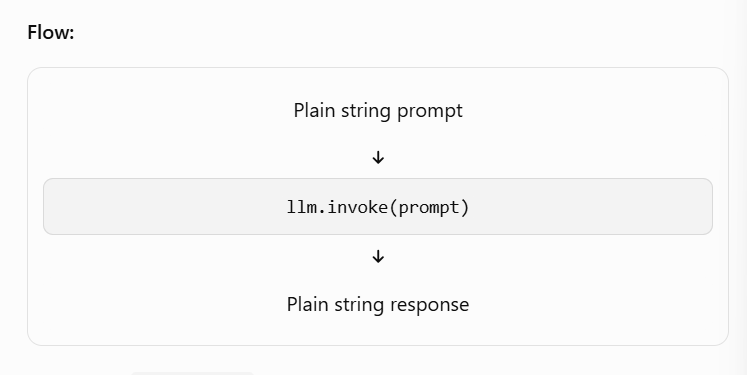

# 2. Program B — Chat Model

In [4]:
%pip install -q -U langchain-openai

In [5]:
from google.colab import userdata
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

# Connect to NVIDIA API
chat_model = ChatOpenAI(
    model="nvidia/nemotron-3.5-lightning-30b-a3b",
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=userdata.get("NVIDIA_API_KEY"),
    temperature=0.3,
    max_tokens=150
)

# Structured messages
messages = [
    SystemMessage(
        content="You are a helpful AI tutor."
    ),
    HumanMessage(
        content="Explain Large Language Models in simple words."
    )
]

# Invoke the chat model
response = chat_model.invoke(messages)

# Output: AIMessage
print(response.content)
print(type(response))


<class 'langchain_core.messages.ai.AIMessage'>


In [6]:
response = chat_model.invoke(
    "Explain tokenization in simple words."
)

print(response.content)

Likewise, a chat model can work with LangChain prompt templates:

In [7]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an LLM tutor."),
    ("human", "Explain {topic} for a beginner.")
])

chain = prompt | chat_model | StrOutputParser()

result = chain.invoke({
    "topic": "self-attention"
})

print(result)

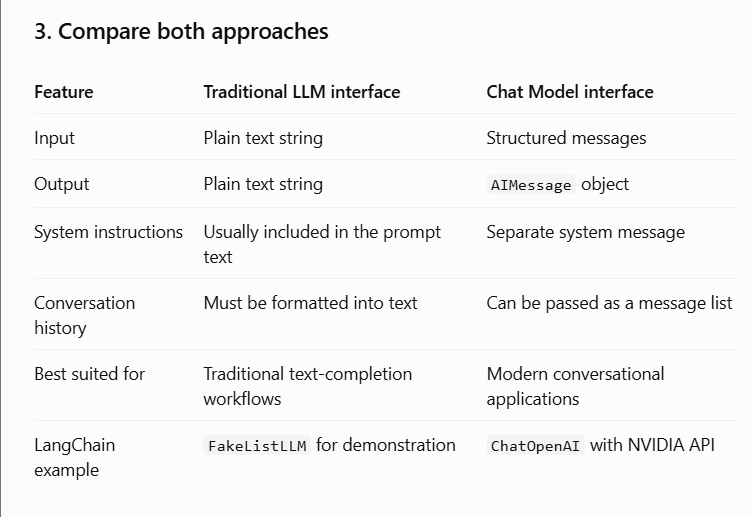